# 01 · Análisis Exploratorio de Datos (EDA) de la data cruda y su transformación

Este notebook trabaja con la data **cruda** extraída de yahoo finance y se analizan los siguientes aspectos: 
- Calidad y limpieza de los de datos: negativos, faltantes, análisis estadístico de series temporales.
- División de la data en entrenamiento, validación y test.
- Transformación: Mediante pruebas estadísticas como ADF, Correlation Spearman, etc se determina el tipo de transfromación para cada variable (retornos logarítmicos o diferencias).

## 0. Configuración

In [1]:
import sys
from pathlib import Path

# La raíz del proyecto es la carpeta que contiene `src/` (funciona se ejecute desde la raíz o desde notebooks/)
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

In [2]:
RAIZ

WindowsPath('d:/OneDrive - SUPERINTENDENCIA DE BANCOS/Escritorio/Proyecto_final_ML/proyecto_final_ml_wti')

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import importlib

from src import config as cfg
import statsmodels.api as sm
from src import load_clean as lc
from src import eda_utils as eda
from src import download_data as dd
from src import preprocessing as pp

from pandas.tseries.holiday import USFederalHolidayCalendar, GoodFriday

In [66]:
importlib.reload(cfg)
importlib.reload(lc)
importlib.reload(dd)
importlib.reload(eda)
importlib.reload(pp)

<module 'src.preprocessing' from 'd:\\OneDrive - SUPERINTENDENCIA DE BANCOS\\Escritorio\\Proyecto_final_ML\\proyecto_final_ml_wti\\src\\preprocessing.py'>

## 1. Carga de la data cruda

In [10]:
dd.main()

[*********************100%***********************]  1 of 1 completed


Descarga completada.
Observaciones: 4233
Primera fecha: 2010-01-04
Última fecha: 2026-10-30

Datos guardados en: D:\OneDrive - SUPERINTENDENCIA DE BANCOS\Escritorio\Proyecto_final_ML\proyecto_final_ml_wti\data\raw\wti_market_data_20261112.csv
Metadatos guardados en: D:\OneDrive - SUPERINTENDENCIA DE BANCOS\Escritorio\Proyecto_final_ML\proyecto_final_ml_wti\data\raw\wti_market_metadata_20261112.json

Valores faltantes por serie:
Ticker
WTI    0
dtype: int64


In [11]:
base = lc.load_raw()
print(base.shape, base.index.min().date(), "->", base.index.max().date())
base.head()

(4233, 1) 2010-01-04 -> 2026-10-30


,WTI
Date,
2010-01-04,81.510002
2010-01-05,81.769997
2010-01-06,83.180000
2010-01-07,82.660004
2010-01-08,82.750000


In [12]:
base.index = pd.to_datetime(base.index)
base = base.sort_index()
assert base.index.is_unique

Se extraen los precios de cierre diarios de las variables financieras consideradas en el proyecto. La base contiene 4.233 observaciones entre el 4 de enero de 2010 y el 30 de octubre de 2026. En el caso del WTI, se utiliza el símbolo CL=F de Yahoo Finance, que corresponde a una serie continua de futuros. La fecha identifica la sesión de negociación y el valor de WTI representa el precio de cierre, en dólares por barril, del contrato de futuros que la serie sigue en esa fecha. El contrato específico y su mes de entrega pueden cambiar a lo largo del tiempo.


| Variable | Unidades | Descripción |
|---|---|---|
| `Date` | Fecha (AAAA-MM-DD) | Fecha de la sesión de negociación a la que corresponde el precio de cierre observado. Permite ordenar cronológicamente las series y sincronizar las variables financieras. |
| `WTI` | USD por barril (USD/bbl) | Precio de cierre de la serie continua de futuros de petróleo crudo West Texas Intermediate (WTI), descargada de Yahoo Finance mediante el símbolo CL=F. Representa la cotización del contrato de futuros que la serie sigue en esa fecha; no es necesariamente el precio spot ni el precio de entrega física inmediata. |


Entonces, para leer la información de la data se debe leer de la siguiente forma:


***El día X del mes Y del año Z, el precio de cierre reportado para la serie continua de futuros de petróleo crudo WTI (CL=F) fue de $M por barril.***

La fecha corresponde a la sesión de negociación. El precio es el cierre del contrato que la serie continua sigue en esa fecha; no significa necesariamente que se comprara petróleo físico a ese precio.

Un contrato de futuros es un acuerdo estandarizado para comprar o vender una cantidad determinada de petróleo en un mes futuro, bajo condiciones definidas por el mercado. Los contratos tienen distintos meses de entrega y se negocian diariamente. Como CL=F es una serie continua, va siguiendo contratos sucesivos conforme se acercan sus vencimientos; por eso, cada observación diaria no necesariamente corresponde al mismo contrato.

### 1.1 Calidad de datos faltantes,ceros y negativos

In [14]:
# El índice debe ser datetime, ordenado y sin duplicados
print(base.index.dtype, base.index.is_monotonic_increasing, base.index.duplicated().sum())

datetime64[us] True 0


In [15]:
eda.chequeo_calidad(base).T

,WTI
min,-37.630001
n_<=0,1.000000
n_inf,0.000000
n_nulos,0.000000
n_dias_sin_cambio,14.000000


El chequeo de calidad de la serie WTI muestra que el valor mínimo es −$37,63 por barril y que existe un solo valor menor o igual a cero. No se detectan valores infinitos ni datos nulos. También se identifican 14 días sin variación en el precio, que conviene revisar para confirmar que sean observaciones legítimas y no valores repetidos por algún problema de descarga o relleno.

In [16]:
lc.summarize_negative_values(base)

,cantidad,porcentaje
WTI,1,0.02


In [17]:
lc.rows_with_negative_values(base)

,WTI
Date,
2020-04-20,-37.630001


Se analizan los valores negativos que pudieran afectar las transformaciones de retornos y se encuentra un único valor negativo en la serie, correspondiente al 20 de abril de 2020. Este valor se relaciona con las condiciones excepcionales del mercado petrolero durante la pandemia de COVID-19: la caída abrupta de la demanda y el exceso de oferta elevaron los inventarios y generaron preocupación por la disponibilidad de almacenamiento en Cushing, Oklahoma, punto de entrega del contrato WTI. Además, el contrato de futuros con entrega en mayo estaba próximo a vencer. Algunos operadores que no podían o no querían recibir físicamente el petróleo vendieron sus posiciones a precios negativos, pagando efectivamente para salir del contrato. El cierre de ese contrato fue de −$37,63 por barril.

Por tanto, el valor negativo no debe interpretarse como un error de los datos ni como que todos los tipos de petróleo se vendieron a un precio negativo: corresponde a un contrato específico de futuros de WTI en una situación extraordinaria, cerca de su vencimiento.

Ahora, se van a analizar los días que no muestran grandes variaciones o cambios.

In [18]:
eda.dias_sin_cambio(base)

,serie,fecha_previa,fecha,valor
0,WTI,2010-07-23,2010-07-26,78.980003
1,WTI,2010-11-10,2010-11-11,87.809998
2,WTI,2017-09-14,2017-09-15,49.889999
3,WTI,2018-05-16,2018-05-17,71.489998
4,WTI,2018-11-15,2018-11-16,56.459999
5,WTI,2019-12-04,2019-12-05,58.430000
6,WTI,2020-02-14,2020-02-18,52.049999
7,WTI,2020-04-15,2020-04-16,19.870001
8,WTI,2020-08-17,2020-08-18,42.889999
9,WTI,2021-09-15,2021-09-16,72.610001


La U.S. Energy Information Administration (EIA) (https://www.eia.gov/dnav/pet/hist/RCLC1D.htm) es una agencia independiente del Departamento de Energía de Estados Unidos que recopila y publica información sobre los mercados energéticos. Al comparar los precios de la serie WTI con los valores de futuros publicados por la EIA, no se encontraron errores anormales ni indicios de errores de digitación. Los días sin cambio corresponden a valores de cierre repetidos entre sesiones consecutivas; estos pueden deberse a condiciones del mercado o a diferencias en el registro y publicación de los datos, por lo que no se consideran errores sin evidencia adicional.

### 1.2 Huecos en el calendario

A continuación, se toma la fecha inicial y final de la serie base y se generan las fechas de los feriados federales de Estados Unidos dentro de ese periodo y añade las fechas de Viernes Santo. Luego combina ambas listas y las compara con el índice de base para identificar cuáles de esos feriados aparecen como fechas de observación en la serie. 

Esta comparación ayuda a revisar el calendario, aunque no confirma por sí sola los días oficiales de negociación de los futuros WTI.

In [19]:
inicio = base.index.min()
fin = base.index.max()

feriados_fed = USFederalHolidayCalendar().holidays(
    start=inicio,
    end=fin,
)

viernes_santo = GoodFriday.dates(inicio, fin)

feriados = feriados_fed.union(viernes_santo).sort_values()

print("Feriados generados:", len(feriados))

Feriados generados: 189


In [20]:
base.index = pd.to_datetime(base.index).normalize()

In [21]:
# bdate_range() genera un rango de fechas considerando solo días hábiles (lunes a viernes)
# genera primero todas las fechas de lunes a viernes desde la fecha mínima hasta la máxima de 
# y con .difference(base.index), quita las fechas que sí están en el índice de base. 
# El resultado son las fechas de lunes a viernes que no aparecen en la base.

faltan = pd.bdate_range(base.index.min(), base.index.max()).difference(base.index)
print(len(faltan)); faltan[:20]

157


DatetimeIndex(['2010-01-18', '2010-02-15', '2010-04-02', '2010-05-31',
               '2010-07-05', '2010-09-06', '2010-11-25', '2010-12-24',
               '2011-01-17', '2011-02-21', '2011-04-22', '2011-05-30',
               '2011-07-04', '2011-09-05', '2011-11-24', '2011-12-26',
               '2012-01-02', '2012-01-16', '2012-02-20', '2012-04-06'],
              dtype='datetime64[us]', freq=None)

In [22]:
faltan_sin_feriados = faltan.difference(feriados)

print(len(faltan_sin_feriados))
faltan_sin_feriados[:20]

3


DatetimeIndex(['2012-10-29', '2012-10-30', '2018-12-05'],
              dtype='datetime64[us]', freq=None)

In [23]:
faltan_sin_feriados_df = pd.DataFrame({
    "fecha": faltan_sin_feriados,
})

faltan_sin_feriados_df["dia_semana"] = (
    faltan_sin_feriados_df["fecha"].dt.day_name()
)

In [24]:
faltan_sin_feriados_df

,fecha,dia_semana
0,2012-10-29,Monday
1,2012-10-30,Tuesday
2,2018-12-05,Wednesday


Una vez quitados los feriados federales de USA, se encontró que existen 3 días laborales que se no son feriados y que deben reportar información de mercado dentro de la serie WTI en la que vamos a trabajar, por lo que vamos a validar si aquellos días se encuentran o no en nuestra serie. 

In [25]:

fechas_a_revisar = pd.DatetimeIndex(faltan_sin_feriados_df["fecha"])

faltantes_presentes = fechas_a_revisar.intersection(base.index)

print(f"Fechas que sí están en base: {len(faltantes_presentes)}")
display(faltantes_presentes)

Fechas que sí están en base: 0


DatetimeIndex([], dtype='datetime64[us]', freq=None)

Como se puede observar, ninguna de las tres fechas aparecen en la base madre en la que trabajaremos, y esto se debe a que: 

- Lunes 29 y martes 30 de octubre de 2012 (Huracán Sandy). La Bolsa de Nueva York (NYSE) y demás mercados estadounidenses cerraron sus operaciones por el impacto del huracán Sandy en la costa este. Fue la primera vez desde 1888 que los mercados cerraban durante dos días consecutivos debido a condiciones climáticas.
- Miércoles 5 de diciembre de 2018 (Duelo nacional por George H. W. Bush). El gobierno federal y los principales mercados bursátiles de Estados Unidos suspendieron sus actividades para observar el Día Nacional de Luto tras el fallecimiento del expresidente George H. W. Bush.

### 1.3 Saltos extremos

In [26]:
eda.saltos_extremos(base).T

,0,1,2,3,4
serie,WTI,WTI,WTI,WTI,WTI
fecha_previa,2020-04-21,2020-03-06,2020-04-24,2020-04-17,2020-04-20
fecha,2020-04-22,2020-03-09,2020-04-27,2020-04-20,2020-04-21
precio_previo,10.01,41.279999,16.940001,18.27,-37.630001
precio_actual,13.78,31.129999,12.78,-37.630001,10.01
cambio,3.77,-10.15,-4.160001,-55.900002,47.640001
cambio_pct,37.662332,-24.588178,-24.557265,-305.966065,-126.601116
log_var_abs,0.319634,0.282206,0.281796,NaN,NaN


Todos los saltos extremos  se concentran en el año 2020, durante el choque petrolero de la pandemia: la demanda cayó bruscamente, hubo exceso de oferta y aumentó la preocupación por la capacidad de almacenamiento. El caso más excepcional es el del 20 de abril, cuando el futuro WTI próximo a vencer cerró en −$37,63 por barril; el cambio desde el cierre previo de $18,27 fue de −$55,90. Los movimientos de los días siguientes reflejan el rebote desde ese episodio y la alta volatilidad de esos días.

Los porcentajes alrededor del valor negativo deben interpretarse con cuidado: al pasar de un precio negativo a uno positivo, el porcentaje convencional puede resultar engañoso. Para esos días es más claro comparar los precios y el cambio en dólares por barril. Estos saltos son extremos, pero coherentes con un periodo de mercado excepcional; por sí solos no prueban errores de digitación ni identifican un cambio de contrato.

In [27]:
top10, excluidos = eda.top_movimientos_diarios(base)

display(top10)

,día,cierre_anterior,cierre,retorno_log_%,retorno_simple_%
2020-03-09,Monday,41.28,31.13,-28.22,-24.59
2020-03-18,Wednesday,26.95,20.37,-27.99,-24.42
2020-03-19,Thursday,20.37,25.22,21.36,23.81
2020-04-02,Thursday,20.31,25.32,22.05,24.67
2020-04-22,Wednesday,10.01,13.78,31.96,37.66
2020-04-23,Thursday,13.78,16.50,18.01,19.74
2020-04-27,Monday,16.94,12.78,-28.18,-24.56
2020-04-29,Wednesday,12.34,15.06,19.92,22.04
2020-04-30,Thursday,15.06,18.84,22.39,25.10
2020-05-05,Tuesday,20.39,24.56,18.61,20.45


Tu tabla muestra que los 10 mayores movimientos logarítmicos calculables se concentran entre marzo y mayo de 2020. Hay caídas fuertes, como el −28,22 % del 9 de marzo, y rebotes, como el +31,96 % del 22 de abril. Esa concentración refleja la volatilidad extraordinaria del mercado petrolero durante la pandemia, cuando se desplomó la demanda y aumentó la preocupación por el almacenamiento.

### 1.4 Resumen estadístico

In [28]:
eda.descriptivos_precios(base).T

serie,WTI
n,4233
media,72.215195
std,20.731412
CV,0.287078
min,-37.630001
fecha_min,2020-04-20
p25,55.91
mediana,72.199997
p75,89.230003
max,123.699997


In [29]:
display(eda.estadisticos_por_anio(base, "WTI"))

,count,mean,std,min,median,max
Date,,,,,,
2010,252,79.61,5.19,68.01,79.74,91.51
2011,252,95.11,8.08,75.67,95.83,113.93
2012,250,94.21,7.67,77.69,92.70,109.77
2013,252,98.05,5.43,86.68,96.61,110.53
2014,252,92.91,13.37,53.27,97.74,107.26
2015,252,48.76,6.79,34.73,47.95,61.43
2016,250,43.44,6.70,26.21,45.06,54.06
2017,251,50.85,3.91,42.53,50.42,60.42
2018,251,64.95,6.68,42.53,66.22,76.41


### 1.5 Gráfica de la serie cruda

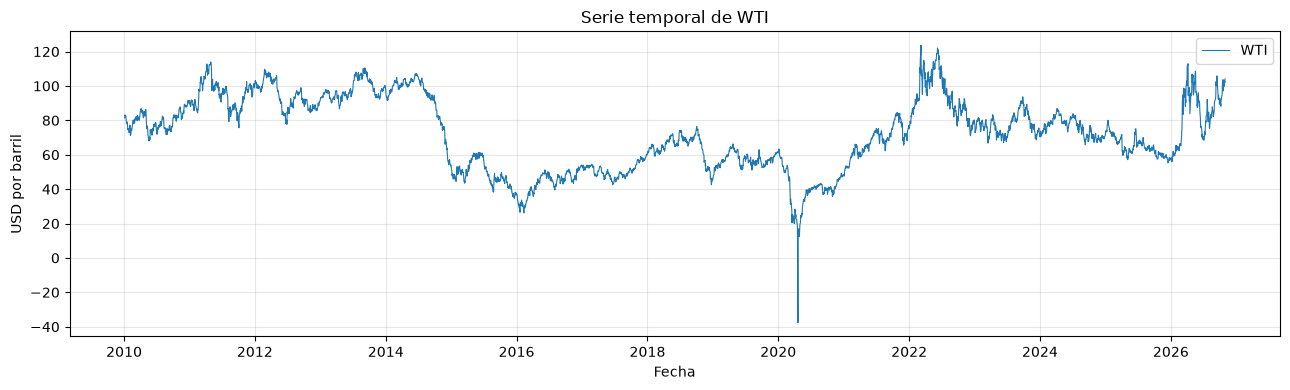

In [30]:
eda.graficar_serie_temporal(base["WTI"], nombre="WTI", unidad="USD por barril")

### 1.6 Tranformación de la serie

En la sección 1.1 se identificó un único precio negativo (20-abr-2020, −37.63 USD), producto del vencimiento del contrato de mayo y la falta de capacidad de almacenamiento. Como el logaritmo no está definido para valores ≤ 0, se elimina esta observación (1 de 4,233). El retorno del 21-abr-2020 se calcula respecto al 17-abr-2020 y se conserva como evento extremo real.

La serie de precios se transforma en retornos logarítmicos diarios (en %):


$$r_t = 100 \cdot \ln\left(\frac{P_t}{P_{t-1}}\right)$$

Se elige esta transformación porque:


- los retornos logarítmicos no dependen de la escala del precio y se interpretan como variación porcentual aproximada;
- son aditivos en el tiempo (el retorno de varios días es la suma de los retornos diarios);
- son la variable estándar en los modelos ARIMA/GARCH y en la literatura de pronóstico financiero.

In [31]:
base1,filas_eliminadas=eda.drop_nonpositive_rows(base)

In [32]:
base1

,WTI
Date,
2010-01-04,81.510002
2010-01-05,81.769997
2010-01-06,83.180000
2010-01-07,82.660004
2010-01-08,82.750000
...,...
2026-10-26,101.760002
2026-10-27,99.900002
2026-10-28,102.779999


In [33]:
filas_eliminadas

,WTI
Date,
2020-04-20,-37.630001


In [34]:
# La decisión vive en src/config.py (TRANSF). Si cambia el diagnóstico, se edita allí.
pd.Series(cfg.transf, name="transformación")

WTI    logret
Name: transformación, dtype: str

In [35]:
base_ret=pp.build_returns(base1)

In [36]:
base_ret

,WTI
Date,
2010-01-05,0.003185
2010-01-06,0.017097
2010-01-07,-0.006271
2010-01-08,0.001088
2010-01-11,-0.002783
...,...
2026-10-26,-0.014730
2026-10-27,-0.018447
2026-10-28,0.028421


## 2.División temporal de los datos

En series de tiempo no se puede dividir la muestra de forma aleatoria (k-fold clásico), porque el modelo usaría observaciones del futuro para predecir el pasado (fuga de información). Por eso la división respeta el orden cronológico:

- Train/Validation o Desarrollo (2010–2024): se usa para el diagnóstico de la serie, la optimización de hiperparámetros y la comparación estadística, mediante validación walk-forward.
- Test final (2025–oct 2026): se reserva y no se utiliza hasta la evaluación final de ambos modelos.

El periodo de desarrollo abarca de enero de 2010 a diciembre de 2024. El test final comprende de enero de 2025 a octubre de 2026 y funciona como verificación fuera de muestra: ambos modelos del proyecto se entrenarán con todo el desarrollo y se evalúan una sola vez en este periodo.

In [38]:
dev_ini=cfg.DEV_INI
dev_fin=cfg.DEV_FIN
test_ini=cfg.TEST_INI
test_fin=cfg.TEST_FIN

In [39]:
dev=base_ret.loc[dev_ini:dev_fin]
test=base_ret.loc[test_ini:test_fin]

In [40]:
dev

,WTI
Date,
2010-01-05,0.003185
2010-01-06,0.017097
2010-01-07,-0.006271
2010-01-08,0.001088
2010-01-11,-0.002783
...,...
2024-12-24,0.012344
2024-12-26,-0.006871
2024-12-27,0.013978


In [41]:
# Verificaciones
assert dev.index.max() < test.index.min()          # sin traslape
assert len(dev) + len(test) == len(base_ret)       # no se pierden observaciones

### 2.1 Validación walk-forward o Time Cross Validation 

Al ser una serie de tiempo indexada con las fechas diarias de negociación y con los retornos calculados, se empleará la validación walk forward con ventana expansiva o Time Series Cross-Validation (TSCV) en machine learning.
en cada fold, el modelo se entrena con todos los datos anteriores al bloque de validación y se evalúa en los 12 meses siguientes.

El intervalo de desarrollo (2010-2024) contiene el train y la validación, los cuales se van alternando en cada fold, es decir: 
- Train: todo lo anterior al bloque de validación de ese fold.
- Validación: los 12 meses siguientes.

Por ejemplo: 

| Fold | Train | Validación |
|---|---|---|
| Rep 1 · Fold 1 | 2010 → 2019 | 2020 |
| Rep 1 · Fold 2 | 2010 → 2020 | 2021 |
| Rep 1 · Fold 3 | 2010 → 2021 | 2022 |
| Rep 1 · Fold 4 | 2010 → 2022 | 2023 |
| Rep 1 · Fold 5 | 2010 → 2023 | 2024 |

Una característica importante de este procedimiento es que **un mismo período puede utilizarse primero como validación y posteriormente formar parte del entrenamiento**.

Por ejemplo, el año **2020**:

- Es utilizado como **validación** en el Fold 1.
- Posteriormente pasa a formar parte del **train** en los Folds 2, 3, 4 y 5.

Por lo tanto, a diferencia de una división tradicional *train/validation*, en Time Series Cross-Validation **no existe un único conjunto de entrenamiento ni un único conjunto de validación**. Ambos van cambiando a medida que se avanza temporalmente.

Este esquema también se conoce como **Expanding Window**, porque la ventana de entrenamiento se va expandiendo en cada iteración.


```text
base_ret (2010 → oct-2026)
│
├── Desarrollo (2010 → 2024)
│   │
│   ├── Train + Validación mediante Time Series Cross-Validation
│   │   └── El train se expande y la validación avanza en el tiempo
│   │
│   └── Se utiliza para:
│       ├── EDA
│       ├── Optimización de hiperparámetros con Optuna
│       └── Comparación y selección estadística de modelos
│
└── Test final (2025 → oct-2026)
    └── Se utiliza una sola vez al final para evaluar
        el desempeño real del modelo seleccionado
```

De esta manera se respeta el orden temporal de los datos: **Pasado → Futuro**

Nunca se utiliza información futura para entrenar un modelo que será evaluado en el pasado.


![Time Series Cross-Validation](../img/imagen1.1.png)

![Time Series Cross-Validation](../img/imagen1.png)

Se obtienen bloques de validación que cubren regímenes distintos (COVID-19, recuperación de 2021, guerra en Ucrania en 2022 y años más estables). Los dos modelos se evalúan exactamente en los mismos folds.

In [48]:
FOLDS = eda.definir_folds()

# Tabla de los folds
tabla_folds = FOLDS.copy()
tabla_folds[["n_train", "n_val"]] = [
    [len(a) for a in eda.indices_fold(dev.index, f)] for f in FOLDS.itertuples()]
for c in ["train_ini", "train_fin", "val_ini", "val_fin"]:
    tabla_folds[c] = tabla_folds[c].dt.date
display(tabla_folds)

assert (FOLDS["val_fin"] <= pd.Timestamp(dev_fin)).all()   # ningún fold toca el test final


,rep,fold,train_ini,train_fin,val_ini,val_fin,n_train,n_val
0,1,1,2010-01-01,2019-12-31,2020-01-01,2020-12-31,2513,252
1,1,2,2010-01-01,2020-12-31,2021-01-01,2021-12-31,2765,252
2,1,3,2010-01-01,2021-12-31,2022-01-01,2022-12-31,3017,251
3,1,4,2010-01-01,2022-12-31,2023-01-01,2023-12-31,3268,250
4,1,5,2010-01-01,2023-12-31,2024-01-01,2024-12-31,3518,252
5,2,1,2010-01-01,2019-06-30,2019-07-01,2020-06-30,2385,252
6,2,2,2010-01-01,2020-06-30,2020-07-01,2021-06-30,2637,252
7,2,3,2010-01-01,2021-06-30,2021-07-01,2022-06-30,2889,252
8,2,4,2010-01-01,2022-06-30,2022-07-01,2023-06-30,3141,251
9,2,5,2010-01-01,2023-06-30,2023-07-01,2024-06-30,3392,250


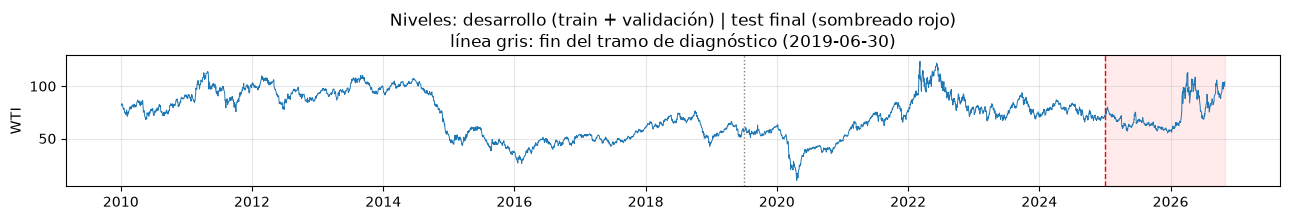

In [57]:
eda.graficar_niveles_con_cortes(base1)

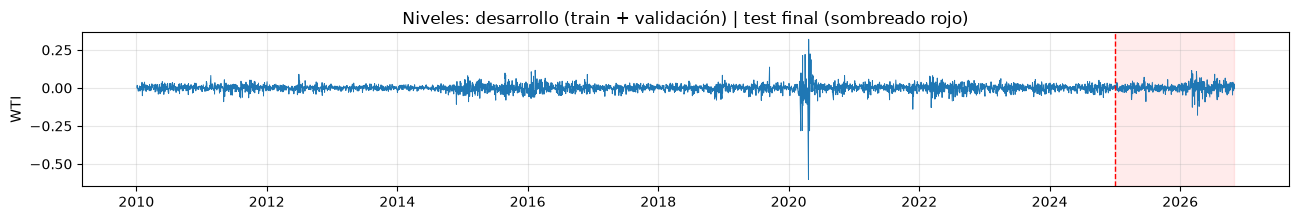

In [58]:
eda.graficar_niveles_con_cortes(base_ret,columnas=["WTI"], mostrar_eda=False)

### 2.2 Tramo para diagnósticos: 2010-2019 (train del primer fold)

Las pruebas que orientan la elección del modelo base (estacionariedad, estacionalidad, ACF/PACF, Ljung-Box y ARCH-LM) se aplicarán al tramo enero 2010 – junio 2019, el cual corresponde al periodo de entrenamiento más corto de todos los folds (Rep 2 · Fold 1). 

Así, ninguna decisión de modelado usa información de los bloques de validación ni del test final.

In [60]:
EDA_FIN = FOLDS["train_fin"].min()          # = 2019-06-30, el train más corto
train_ret = base_ret.loc[:EDA_FIN]

print(f"Tramo de diagnóstico: {train_ret.index.min().date()} → {train_ret.index.max().date()} "
      f"({len(train_ret)} obs, {100*len(train_ret)/len(dev):.1f}% del desarrollo)")
assert train_ret.index.max() < FOLDS["val_ini"].min()   # no toca ninguna validación

Tramo de diagnóstico: 2010-01-05 → 2019-06-28 (2385 obs, 63.3% del desarrollo)


In [61]:
train_ret

,WTI
Date,
2010-01-05,0.003185
2010-01-06,0.017097
2010-01-07,-0.006271
2010-01-08,0.001088
2010-01-11,-0.002783
...,...
2019-06-24,0.008151
2019-06-25,-0.001210
2019-06-26,0.026450


El tramo de diagnóstico (EDA) comprende desde el 5 de enero de 2010 hasta el 28 de junio de 2019, con un total de 2.385 observaciones, que representan el 63,3 % del conjunto de desarrollo (2010–2024).

Este período se utiliza para analizar el comportamiento histórico de las series financieras, identificar tendencias, volatilidad, estacionariedad, valores atípicos y relaciones entre variables, antes de realizar la validación temporal y el entrenamiento de los modelos predictivos.

## 3. EDA de la parte de train previa a la validación

### 3.1 Estadística Descriptiva

In [70]:
eda.descriptivos_precios(train_ret).T

serie,WTI
n,2385
media,-0.000139
std,0.020494
CV,-147.132587
min,-0.107942
fecha_min,2014-11-28
p25,-0.010823
mediana,0.000522
p75,0.010951
max,0.116213


El análisis descriptivo de los 2.385 log-retornos diarios del petróleo WTI de la parte de train seleccionada  correspondiente al período del 5 de enero de 2010 al 28 de junio de 2019, presenta los siguientes resultados:

- 	Rendimiento logarítmico promedio diario de aproximadamente -0,014 %, cercano a cero, con una ligera tendencia negativa.
- Volatilidad diaria de 2,05 %, que refleja la dispersión de los rendimientos respecto a su media.
- Mayor caída diaria observada, equivalente a un log-retorno de -10,79 % el 28 de Noviembre de 2014
- El 25 % de los rendimientos diarios fueron inferiores o iguales a -1,08 % en escala logarítmica.
- 	El 50 % de los rendimientos fueron inferiores o iguales a 0,052 %, evidenciando un rendimiento central ligeramente positivo.
- Mayor incremento diario observado, equivalente a un log-retorno de 11,62 % el 12 de Febrero de 2016.
- Asimetría (Skewness = -0,0171): indica que la distribución es prácticamente simétrica, con una ligera asimetría negativa. Por tanto, no se evidencia una inclinación significativa de la distribución hacia rendimientos negativos o positivos.
- Curtosis en exceso (2,9174): indica que la distribución es leptocúrtica, es decir, presenta colas más pesadas que una distribución normal, lo que sugiere mayor frecuencia de movimientos extremos.  Una distribución leptocúrtica significa que existe una mayor presencia de valores extremos (tanto negativos como positivos) en comparación con una distribución normal



### 3.2 Distribución, Estacionariedad, Estacionalidad y otras métricas

Para la estacionariedad se valida que:

- **ADF**: $H_0$ = la serie tiene raíz unitaria (no estacionaria).
- **KPSS**: $H_0$ = la serie es estacionaria.

Se usan las dos porque tienen hipótesis nulas opuestas. La conclusión es fuerte cuando ambas coinciden.

In [ ]:
  - Histograma y Q-Q Plot
       - Asimetría y curtosis
       - Jarque-Bera
       - ADF y KPSS

### 3.3 Dependencia temporal de los retornos

In [ ]:
- ACF de r_t
       - PACF de r_t
       - Ljung-Box de r_t

### 3.4 Dependencia temporal de la volatilidad

In [71]:
      - Volatilidad móvil
       - ACF de r_t²
       - Ljun
g-Box de r_t²
       - ARCH-LM sobre residuos de la media

IndentationError: unexpected indent (4235014827.py, line 1)

In [ ]:
### 3.5 Conclusiones del EDA
       - Estacionariedad
       - Normalidad y colas pesadas
       - Predictibilidad lineal de la media
       - Persistencia de volatilidad
       - Modelos estadísticos candidatos

In [ ]:
3. Diagnóstico de la serie              ← solo sobre 2010–2019
   3.1 Estacionariedad (ADF / KPSS: precio, log precio, retorno)
   3.2 Estacionalidad (día de la semana, mes, STL)
   3.3 ACF / PACF de r_t  + Ljung-Box
   3.4 ACF de r_t²  + Ljung-Box + ARCH-LM
   3.5 Conclusiones del EDA → elección ARIMA o GARCH

In [ ]:
# Valores <= 0, infinitos, nulos y precios repetidos por serie (todo el rango)
display(eda.chequeo_calidad(base1))

for c in base1.columns:
    malos = base1.index[base1[c] <= 0]
    if len(malos):
        print(c, [d.date() for d in malos])

print("\nValores <= 0 por tramo (train y val deben quedar limpios):")
for k, (a, b) in cfg.splits.items():
    print(k, (base1.loc[a:b] <= 0).sum().to_dict())

Se analizan valor negativos que pudieran afectar las transformaciones de retornos en cada fase del modelo: train, validación y test. 

> train: ("2010-01-04", "2018-12-31")

> val:   ("2019-01-01", "2019-12-31")

> test:  ("2020-01-01", "2026-10-20").

Se encontró lo siguiente:

1. Solo el WTI tiene un valor ≤ 0, el del 20/04/2020, que cae en test.
2. Train y validación están limpios, así que el diagnóstico de transformaciones y los estadísticos del EDA no se ven afectados.
3. No hay nulos ni infinitos en ninguna serie.
4. El resto de las series son positivas, así que el log-retorno es válido para todas. 
5. TNX: el mínimo de 0,499 corresponde a la tasa en porcentaje (los mínimos de 2020), así que tu escala es consistente. Lo del “×10” que mencioné antes no aplica a tus datos.

A continuación, para cada año se analiza la cantidad de observaciones, y no se sobservan variaciones interanuales significativas.

In [ ]:
eda.observaciones_por_anio(base1)

### 1.5 Niveles y cortes de la partición

La partición es temporal y se fijó **antes de explorar** los datos, de modo que ninguna decisión de diseño depende de lo que ocurre en validación o prueba. La línea roja marca el fin de train (31/12/2018) y la naranja el fin de validación (31/12/2019).

| Tramo | Periodo | Observaciones | % del total | Uso |
|---|---|---|---|---|
| **Train** | 04/01/2010 – 31/12/2018 | 2.260 | 53,5 % | Análisis exploratorio, elección de la transformación, selección de K y ajuste de los modelos |
| **Validación** | 02/01/2019 – 31/12/2019 | 252 | 6,0 % | Evaluación del modelo ya ajustado y elección de hiperparámetros |
| **Test** | 02/01/2020 – 20/10/2026 | 1.709 | 40,5 % | Evaluación final, abierta una sola vez |


In [ ]:
eda.graficar_niveles_con_cortes(base1)

1. **Train** abarca el periodo de precios altos del petróleo (WTI cerca de 80-110 USD hasta mediados de 2014), el colapso de 2014-2016 (hasta alrededor de 30 USD) y una recuperación parcial hacia 2018. También incluye el cambio de nivel del DXY desde 2014 y las alzas sostenidas del SP500.
2. **Validación (2019)** es un año corto y relativamente tranquilo, con el VIX bajo y el WTI en una banda estrecha. No representa los regímenes del test, por lo que sirve para elegir hiperparámetros pero no para anticipar el desempeño posterior.
3. **Test** contiene eventos que nunca ocurren en train:
   * el precio **negativo del WTI** (−37,63 USD el 20/04/2020) y el pico del VIX cercano a 80 en marzo de 2020;
   * un máximo del WTI cercano a 120 USD en 2022 y del gas natural cercano a 10 USD;
   * niveles de **GOLD, SP500 y TNX** muy por fuera del rango de train: el oro supera los 5.000 USD frente a un máximo cercano a 2.000 en train, y el SP500 pasa de 7.000 puntos frente a cerca de 3.000.
4. **Consecuencia para el modelado:** los niveles del test quedan fuera del rango observado en train, por lo que un modelo entrenado sobre niveles tendría que extrapolar. Esto refuerza la decisión de trabajar con retornos y diferencias, que sí se mantienen en un rango comparable entre tramos.

**Ventanas de evaluación dentro del test**

El test se subdivide en cinco ventanas, sin solapes y que lo cubren por completo (verificado con `verificar_particion`). Se usarán solo en la evaluación final para ver el desempeño del modelo en regímenes distintos.

| Ventana | Periodo | Característica observada en el gráfico |
|---|---|---|
| `covid` | 01/01/2020 – 31/12/2020 | caída del WTI, precio negativo del 20/04 y pico del VIX |
| `rec_2021` | 01/01/2021 – 31/12/2021 | recuperación sostenida del WTI y de las bolsas |
| `rob_2022` | 01/01/2022 – 31/12/2022 | máximos del WTI, el DXY y el gas natural |
| `calma_23_25` | 01/01/2023 – 31/12/2025 | niveles más estables y volatilidad menor |
| `rec_2026` | 01/01/2026 – 20/10/2026 | repunte reciente del WTI y fuerte alza del oro |

## 2. EDA descriptivo para parte train

In [ ]:
part = lc.particionar(base1)

In [ ]:
px_train = part["train"]          # precios de train: único insumo de las partes C y D
px_train.shape, px_train.index.min().date(), px_train.index.max().date()

### 2.1 Análisis descriptivo de train

In [ ]:
# Descriptivos de los niveles: ¿qué escala tiene cada serie y cuándo tocó sus extremos?
eda.descriptivos_precios(px_train).round(3)

La tabla describe los **precios de cierre** de las siete series en el periodo de entrenamiento (2.260 observaciones por serie) desde el 04 de Enero de 2010 al 31 de Diciembre de 2018. 

Sirve para conocer la escala y los extremos de cada variable. No se usa para modelar, porque los niveles se transforman en la sección 4.

**Escala y dispersión.** Las series están en unidades distintas: el SP500 promedia 1.856 puntos, el oro 1.342 USD/oz, el WTI 74,2 USD/bbl y el TNX 2,42 %, por lo que no son comparables directamente. El coeficiente de variación (CV) sí permite comparar la dispersión relativa:
* **Mayor dispersión:** VIX (0,34), WTI (0,30) y SP500 (0,28).
* **Dispersión intermedia:** NG (0,24) y TNX (0,23).
* **Menor dispersión:** GOLD (0,14) y DXY (0,09). El dólar es la serie más estable en niveles.

**Forma de la distribución.**
* **VIX:** la única con asimetría positiva marcada (1,67) y curtosis en exceso positiva (3,42). Hay muchos días tranquilos (mediana 15,6, con mínimo de 9,1) y picos esporádicos hasta 48.
* **GOLD:** asimetría positiva moderada (0,96) y curtosis casi nula.
* **WTI, DXY y SP500:** curtosis negativa fuerte (−1,38, −1,48 y −1,04) y asimetría cercana a cero. Son distribuciones aplanadas, no con colas pesadas. Reflejan tendencias y cambios de régimen (WTI y DXY en 2014, SP500 con alza sostenida), no el comportamiento extremo que interesa modelar. Por eso la media y la desviación de los niveles describen mal estas series.
* **WTI:** la media (74,2) queda por debajo de la mediana (77,0) y el rango intercuartílico es muy amplio (51,3 a 94,8), coherente con los dos regímenes de precio alto y bajo.

**Extremos.**

| Serie | Mínimo (fecha) | Máximo (fecha) | Lectura |
|---|---|---|---|
| WTI | 26,21 (11/02/2016) | 113,93 (29/04/2011) | mínimo dentro de la caída 2014-2016 |
| VIX | 9,14 (03/11/2017) | 48,00 (08/08/2011) | máximo en 2011, mínimo en un periodo de calma |
| DXY | 72,93 (29/04/2011) | 103,29 (20/12/2016) | mínimo al inicio, máximo tras el cambio de nivel de 2014-2015 |
| GOLD | 1.050,8 (17/12/2015) | 1.888,7 (22/08/2011) | máximo en 2011 y mínimo en 2015 |
| TNX | 1,366 (08/07/2016) | 3,994 (05/04/2010) | máximo al inicio y mínimo en 2016 |
| SP500 | 1.022,6 (02/07/2010) | 2.930,8 (20/09/2018) | mínimo al inicio y máximo al final, tendencia alcista |
| NG | 1,639 (03/03/2016) | 6,149 (19/02/2014) | máximo en 2014 y mínimo en 2016 |

Varios mínimos coinciden en 2015-2016 (WTI, GOLD, TNX, NG), lo que apunta a un episodio común de precios bajos. El máximo del WTI y el mínimo del DXY caen el mismo día (29/04/2011), una coincidencia que sugiere una relación inversa entre ambos, aunque un solo día no basta para afirmarla. El SP500 pasa de su mínimo a su máximo en el periodo, un factor de casi 3 (de 1.022 a 2.930).

**Conclusión.** Las series tienen escalas distintas, regímenes de nivel y tendencias, y los extremos de varias coinciden con los grandes movimientos de 2011 y 2014-2016. Esto confirma que los niveles no son un insumo adecuado y justifica transformarlos.

In [ ]:
# Evolución relativa de todas las series en un solo gráfico
eda.graficar_base100(px_train)

La figura presenta la evolución relativa de varios indicadores financieros y materias primas (WTI, VIX, DXY, GOLD, TNX, S&P500 y NG) entre 2010 y 2019, normalizados a una base 100 al inicio del período y representados en escala logarítmica. Esta transformación permite comparar la dinámica relativa de activos con diferentes magnitudes y volatilidades.

Se observa que el S&P500 registra el mejor desempeño acumulado durante el período, pasando de una base de 100 a niveles superiores a 200, lo que refleja una tendencia alcista sostenida. El índice del dólar (DXY) y el oro (GOLD) muestran una evolución más estable, con incrementos moderados respecto al valor inicial.

En contraste, el WTI exhibe una elevada volatilidad y una marcada caída entre 2014 y 2016, período asociado al colapso de los precios internacionales del petróleo. De manera similar, el gas natural (NG) presenta fluctuaciones significativas y una tendencia general descendente respecto a su nivel inicial. El rendimiento de los bonos del Tesoro estadounidense a 10 años (TNX) también evidencia una trayectoria decreciente durante buena parte del horizonte analizado, con cierta recuperación hacia 2017-2018.

El índice de volatilidad (VIX) es la serie más errática, caracterizada por fuertes picos transitorios que reflejan episodios de incertidumbre en los mercados financieros. Estas oscilaciones son considerablemente más pronunciadas que las observadas en los demás activos.

### 2.2 Tendencias y regímenes (medias móviles)

In [ ]:
# Tendencias y cambios de régimen: media móvil de 63 y 252 días
eda.graficar_medias_moviles(px_train)

Las medias móviles de 63 y 252 días permiten identificar claramente los regímenes de tendencia de cada activo. El S&P500 mantiene una tendencia alcista sostenida durante casi todo el período, mientras que WTI y NG presentan cambios cíclicos marcados y episodios de alta volatilidad. El VIX muestra un comportamiento predominantemente reversivo con picos asociados a episodios de estrés financiero. Por su parte, DXY evidencia un fortalecimiento estructural desde 2014, mientras que GOLD y TNX alternan fases alcistas y bajistas sin una tendencia dominante persistente.

Desde la perspectiva de modelización, las series exhiben comportamientos heterogéneos en tendencia y volatilidad, lo que justifica trabajar con retornos o variaciones porcentuales en lugar de niveles, así como considerar posibles cambios de régimen y dependencia temporal en los análisis posteriores.

### 2.3 Histogramas y Diagramas de Caja

In [ ]:
# Distribución de los niveles (no normal, con varias modas por los cambios de régimen)
eda.graficar_histogramas_niveles(px_train)

In [ ]:
# Cambios de nivel y de dispersión entre años
eda.graficar_boxplot_anual(px_train)

Los diagramas de caja evidencian cambios significativos en la distribución de las variables a lo largo del tiempo. El S&P500 presenta un incremento sostenido de su mediana entre 2010 y 2018, reflejando una tendencia alcista consistente. En contraste, WTI y NG muestran una reducción importante de sus niveles centrales después de 2014, acompañada de una elevada dispersión, lo que sugiere una mayor exposición a choques de mercado.

Por su parte, el VIX exhibe la mayor cantidad de valores atípicos y una fuerte asimetría positiva, característica de una variable asociada a episodios esporádicos de alta incertidumbre financiera. El DXY muestra un desplazamiento de su distribución hacia niveles más altos a partir de 2015, mientras que GOLD y TNX alternan períodos de expansión y contracción sin mantener una tendencia uniforme durante todo el horizonte analizado.

### 2.4 WTI por año, valles y caídas

In [ ]:
# WTI por año y mayor caída (pico a valle) de cada serie dentro de train
display(eda.estadisticos_por_anio(px_train, "WTI"))
eda.tabla_drawdown(px_train)

* **Distribución de los niveles:** no es normal ni estable; cambia entre años (boxplots), así que media y desviación globales no describen bien ninguna época.
* **Escala:** cada serie está en unidades distintas (USD, puntos de índice, % de tasa), por eso no se comparan directamente.
* **Estacionalidad:** revisa si el gas natural muestra un patrón mensual en el nivel (índice estacional distinto de 1). (falta ver estacionalidad)
* **Conclusión:** los niveles tienen tendencia y regímenes, y las correlaciones entre ellos son espurias. Hay que transformarlos, y la parte D decide cómo.

## 3. Elección de la transformación (se usa train)

Sea $P_t$ el nivel observado de una serie en el periodo $t$ y $P_{t-1}$ el nivel en la observación anterior. Las transformaciones comparan ambos niveles para describir el cambio entre observaciones consecutivas.

**Retorno simple.** El retorno simple mide el cambio relativo respecto al valor inicial:

$$
r_t = \frac{P_t-P_{t-1}}{P_{t-1}} = \frac{P_t}{P_{t-1}}-1.
$$

Se expresa como proporción; multiplicarlo por 100 lo expresa en porcentaje. Por ejemplo, $r_t=0{,}02$ equivale a un aumento del 2 %. Esta medida requiere $P_{t-1}\ne 0$ y su interpretación porcentual usual supone un nivel inicial positivo.

**Log-retorno.** El log-retorno es la diferencia de los logaritmos de dos niveles consecutivos:

$$
g_t = \ln(P_t)-\ln(P_{t-1}) = \ln\!\left(\frac{P_t}{P_{t-1}}\right)=\ln(1+r_t).
$$

Es aditivo en el tiempo: el log-retorno acumulado entre $t-k$ y $t$ es $\sum_{j=t-k+1}^{t} g_j=\ln(P_t/P_{t-k})$. Para cambios pequeños, $\ln(1+r_t)\approx r_t$, por lo que log-retorno y retorno simple son cercanos; para recuperar el retorno simple exacto se usa $r_t=e^{g_t}-1$. El log-retorno requiere niveles estrictamente positivos en ambos periodos. Por esta razón no está definido para el WTI negativo del 20/04/2020; la construcción deja esos casos como valores faltantes y el análisis de selección de transformación se realiza solo con train, donde los niveles son positivos.

**Primera diferencia.** La diferencia mide el cambio absoluto en las unidades originales:

$$
\Delta P_t = P_t-P_{t-1}.
$$

A diferencia del retorno, no divide por el nivel anterior: un valor de $\Delta P_t$ representa barriles/dólares, puntos de índice o, para TNX, puntos porcentuales de rendimiento (por ejemplo, $0{,}10$ equivale a 10 puntos básicos). La diferencia conserva la escala de cada variable y puede ser más apropiada cuando interesan cambios absolutos o cuando el nivel puede acercarse a cero.

En este notebook se comparan la primera diferencia y el log-retorno para elegir la escala de cada serie. En el diagnóstico, el log-retorno se calcula como $\ln(P_t)-\ln(P_{t-1})$; se reporta como proporción, no multiplicado por 100. La primera observación de cada serie no tiene periodo previo y, por tanto, su transformación queda indefinida.

A continuación vamos a determinar el tipo de transformación que vamos a aplicar para estandarizar las variables dado que cada una se encuentra en diferentes unidades de medida. Los indicadores que se van a aplicar son los siguientes:


| Indicador | Qué mide | Límites y Criterios de Decisión |
| :--- | :--- | :--- |
| **`ADF_p`** (Augmented Dickey-Fuller - p-valor) | La estacionariedad de la serie (prueba la presencia de raíz unitaria). | **$< 0.05$**: Indica que la serie es estacionaria.<br>**$\ge 0.05$**: La serie no es estacionaria (posee raíz unitaria). |
| **`KPSS_p`** (Kwiatkowski-Phillips-Schmidt-Shin - p-valor) | La estacionariedad (prueba complementaria a ADF, con hipótesis nula invertida). | **$> 0.05$** (con tope de referencia en $0.10$): Indica que la serie es estacionaria.<br>**$\le 0.05$**: La serie no es estacionaria. |
| **`asimetria`** | El sesgo o grado de asimetría en la distribución de los datos. | **$> 0$**: Asimetría positiva (cola derecha más larga, sesgo hacia valores altos).<br>**$= 0$**: Distribución simétrica.<br>**$< 0$**: Asimetría negativa (cola izquierda más larga, sesgo hacia valores bajos). |
| **`curtosis`** (en exceso) | El peso de las colas y la concentración alrededor de la media respecto a una distribución normal. | **$> 0$**: Leptocúrtica (colas más pesadas que la normal, mayor propensión a *outliers* o valores extremos).<br>**$= 0$**: Mesocúrtica (distribución normal).<br>**$< 0$**: Platicúrtica (colas más ligeras que la normal, valores más uniformemente distribuidos). |
| **`corr_abs_nivel`** | La correlación lineal entre la magnitud absoluta de la variación y el nivel de la serie. | **$\approx 0$ (entre $-0.1$ y $0.1$)**: Escala adecuada (volatilidad independiente del precio).<br>**$> 0.1$**: Movimientos mayores cuando el precio es alto.<br>**$< -0.1$**: Movimientos mayores cuando el precio es bajo. |
| **`spearman_abs_nivel`** | La relación monotónica entre el cambio absoluto y el nivel (versión robusta a *outliers*). | **$\approx 0$ (entre $-0.1$ y $0.1$)**: Escala adecuada sin distorsión por valores extremos.<br>**$> 0.1$**: Relación de escala creciente (mayor volatilidad a mayor precio, resistente a *outliers*).<br>**$< -0.1$**: Relación de escala decreciente (mayor volatilidad a menor precio, resistente a *outliers*). |
| **`ratio_std_alto_bajo`** | La estabilidad de la dispersión comparando la desviación estándar del tercil más alto del nivel frente al tercil más bajo. | **$\approx 1$**: Escala estable entre niveles de precio.<br>**$> 1$**: La variabilidad es mayor en la zona de precios altos (sugiere aplicar logaritmo).<br>**$< 1$**: La variabilidad es mayor en la zona de precios bajos. |

### 3.1 Comparación de métricas de las transformaciones: nivel, diferencia y log-retorno

In [ ]:
diag = eda.diagnostico_transformaciones(px_train)
print(diag.to_string(index=False))

A partir de los resultados de las pruebas de estacionariedad ADF y KPSS, los coeficientes de asimetría y curtosis, la correlación entre las variaciones absolutas y los niveles, y la relación de desviaciones estándar entre regímenes de valores altos y bajos, se evaluó la conveniencia de aplicar diferencias absolutas o rendimientos logarítmicos a las siete series analizadas.

Los resultados sugieren utilizar rendimientos logarítmicos para DXY, GOLD, SP500 y NG, debido a sus propiedades de estacionariedad, mayor estabilidad relativa de dispersión y mejoras en las características distributivas respecto a las diferencias absolutas.

Para TNX, se recomienda aplicar diferencias absolutas, tanto por la interpretación económica de las variaciones de los rendimientos de los bonos del Tesoro como por los resultados de estabilidad y curtosis.

En el caso del WTI, los rendimientos logarítmicos resultan apropiados cuando el objetivo es analizar variaciones relativas del precio; sin embargo, las diferencias absolutas presentan mejores indicadores de estabilidad de dispersión, por lo que la elección deberá considerar el propósito del modelo y verificar la positividad de los precios.

Para el VIX, los rendimientos logarítmicos mejoran los indicadores de asimetría, curtosis y dispersión respecto a las diferencias absolutas. No obstante, dada la naturaleza del índice como medida de volatilidad y los resultados contradictorios de estacionariedad en niveles, se recomienda evaluar adicionalmente la transformación logarítmica del nivel, especialmente en modelos que busquen capturar persistencia o reversión a la media.

Finalmente, debido a las distintas unidades de medida de las series, se recomienda considerar una estandarización posterior cuando las características del modelo lo requieran. La elección definitiva deberá complementarse con diagnósticos de autocorrelación, heterocedasticidad, estabilidad temporal y desempeño del modelo estimado.

### 3.2 Comparación gráfica de las transformaciones: nivel, diferencia y log-retorno

Las gráficas se estructuran de la siguiente manera: 

- La **primera columna** muestra la serie original (nivel) y permite analizar la tendencia, los cambios de régimen y la estabilidad de la media (fila 1), la forma de la distribución de los precios (fila 2) y su persistencia mediante la función de autocorrelación (fila 3). Una ACF cercana a 1 en todos los rezagos indica una serie no estacionaria que debe transformarse.
- La **segunda columna** muestra la primera diferencia (variación en unidades de la serie, $P_t − P_{t−1}$) y permite analizar si la serie se vuelve estacionaria y oscila alrededor de cero (fila 1), si su distribución es simétrica o presenta colas pesadas respecto a la normal (fila 2) y si el tamaño del cambio en unidades depende del nivel de la serie (fila 3, mediante la correlación entre |diferencia| y el nivel).
- La **tercera columna** muestra el log-retorno (variación porcentual, $log P_t − log P_{t−1}$) y permite analizar los mismos aspectos que la diferencia, con la ventaja de expresar el cambio en términos relativos: si es estacionaria y estable alrededor de cero, con periodos de volatilidad agrupada (fila 1), si su distribución es simétrica y con colas pesadas (fila 2) y si el tamaño del movimiento porcentual depende del nivel de la serie (fila 3, mediante la correlación entre |log-retorno| y el nivel).

En las filas 2 y 3 se reportan además la asimetría y la curtosis en exceso (fila 2) y el coeficiente de correlación r (fila 3), con la regla de que valores de r entre −0,1 y 0,1 indican una escala adecuada, es decir, una variabilidad independiente del nivel.



In [ ]:
eda.graficar_transformaciones(px_train, 'WTI')

**WTI.** 
1. El nivel no es estacionario: muestra tendencia y dos regímenes de precio (una caída marcada desde mediados de 2014), por lo que la media global (≈ 74 USD) no representa ningún periodo. Su distribución es bimodal, con picos cerca de 48 y 95-100 USD (asimetría −0,15; curtosis −1,38, aplanamiento causado por los regímenes y no por colas pesadas), y su ACF es cercana a 1 en los 40 rezagos (≈ 0,92 al final), lo que indica una persistencia propia de una raíz unitaria. Por eso el nivel no puede usarse como insumo.

2. Tanto la diferencia como el log-retorno oscilan alrededor de cero, son estacionarios y tienen colas más pesadas que la normal (curtosis en exceso de 2,91 y 2,97). La diferencia presenta una ligera asimetría negativa (−0,27) y el log-retorno es simétrico (0,00). Respecto a la escala, el tamaño de la variación en dólares no depende del precio (|diff| vs nivel, r = 0,07), mientras que el movimiento porcentual es mayor cuando el precio es bajo (|logret| vs nivel, r = −0,30), en particular durante 2015-2016, cuando además se observa agrupamiento de volatilidad en el log-retorno.

Por escala, la diferencia resulta más estable; sin embargo, se adopta el log-retorno por su simetría, por expresar la variación en términos relativos comparables entre niveles de precio y por ser la transformación estándar en los modelos GARCH y de riesgo, dejando registrada su dependencia residual del nivel como limitación.

In [ ]:
eda.graficar_transformaciones(px_train, 'VIX')

**VIX.** 

1. El nivel oscila alrededor de su media (≈ 17 puntos) y retorna a ella tras los picos de estrés (2010, 2011, 2015 y 2018), a diferencia del WTI, que cambió de régimen. Su distribución es asimétrica a la derecha (asimetría 1,67; curtosis 3,42), concentrada entre 12 y 16 puntos con una cola larga hasta 48. La ACF parte de 0,95 y decae lentamente hasta ≈ 0,5 en el rezago 40, lo que indica una serie persistente con reversión a la media. Los resultados de estacionariedad en nivel son contradictorios (ADF rechaza la raíz unitaria con p = 0,003, pero KPSS rechaza la estacionariedad con p ≤ 0,01), por lo que se trata de una serie muy persistente y no claramente estacionaria.

2. La diferencia y el log-retorno oscilan alrededor de cero y son estacionarios, pero sus variaciones aumentan cuando el VIX está alto: |diff| vs nivel tiene r = 0,53 y |logret| vs nivel, r = 0,27. Ambas presentan colas muy pesadas, con asimetría positiva (diff: 1,72 y curtosis 21,67; logret: 1,11 y curtosis 7,22), producto de los saltos del 5 de febrero de 2018 (+20 puntos; log-retorno ≈ 0,77).

Se adopta el log-retorno, que reduce a la mitad la dependencia de la escala (0,53 → 0,27) y baja la curtosis de 21,7 a 7,2. La dependencia residual es una característica real de la serie: su volatilidad es mayor cuando el índice es alto.

In [ ]:
eda.graficar_transformaciones(px_train, 'DXY')

**DXY (índice del dólar estadounidense).** Mide el valor del dólar frente a una cesta de seis monedas principales. 

1. Su nivel no es estacionario: se mueve entre 73 y 83 puntos hasta mediados de 2014 y luego cambia de régimen, subiendo a cerca de 100 en 2015 y llegando a un máximo cercano a 103 a finales de 2016, con la media global (≈ 87) por debajo de ambos regímenes. Su distribución es bimodal, con picos cerca de 80 y 95 puntos, que corresponden a esos dos regímenes (asimetría 0,17; curtosis −1,48, aplanamiento causado por los regímenes y no por colas pesadas). La ACF es cercana a 1 en los 40 rezagos (≈ 0,93 al final), propia de una raíz unitaria, y coincide con el resultado de ADF (p = 0,66), que no la rechaza.

2. La diferencia y el log-retorno oscilan alrededor de cero, son estacionarios y tienen distribuciones casi simétricas (asimetría 0,01 y 0,07) con colas moderadamente pesadas (curtosis en exceso de 1,54 y 1,28), menores que las del WTI y el VIX. Respecto a la escala, el tamaño de la variación en puntos aumenta ligeramente con el nivel (|diff| vs nivel, r = 0,12, en el límite del rango de ±0,1), mientras que el movimiento porcentual no depende del nivel (|logret| vs nivel, r = 0,00). Los dos grupos de puntos de la nube (cerca de 80 y de 95) reflejan el tiempo que la serie permaneció en cada régimen, sin que se observe pendiente.

Se adopta el log-retorno, que elimina la dependencia de la escala (r de 0,12 a 0,00), tiene la menor curtosis y la menor asimetría de las dos opciones, y expresa la variación en términos relativos, comparable entre los dos regímenes de nivel de la serie.

In [ ]:
eda.graficar_transformaciones(px_train, 'GOLD')

**GOLD (precio futuro del oro).**  

1. Su nivel no es estacionario: sube desde el 2010 hasta alcanzar un máximo en 2011 y se mantiene alto hasta que cae con fuerza a partir del año 2013 
 y toca un mínimo cercano a 1.050 a finales de 2015. Luego se mueve en una banda estrecha (≈ 1.150-1.360) hasta 2018. La media global (≈ 1.342) no representa ninguna de esas fases. Su distribución tiene asimetría positiva (0,96) y curtosis en exceso casi nula (−0,10), con un pico principal entre 1.200 y 1.300 y un segundo grupo de valores entre 1.600 y 1.800 que corresponde al periodo de precios altos de 2011-2012. La ACF es cercana a 1 en todos los rezagos (≈ 0,90 en el rezago 40), propia de una raíz unitaria, y es coherente con el resultado de ADF (p = 0,31), que no la rechaza.

2. La diferencia y el log-retorno oscilan alrededor de cero y son estacionarios, pero ambos presentan asimetría negativa (−0,99 y −0,76, es decir, caídas más bruscas que las subidas) y colas pesadas (curtosis en exceso de 9,07 y 6,93), con su valor extremo en la caída de 2013 (≈ −140 USD; log-retorno ≈ −0,10). Respecto a la escala, el tamaño del cambio en dólares aumenta con el precio (|diff| vs nivel, r = 0,24), de modo que las variaciones de 2011-2012, con precios altos, son mucho mayores en términos absolutos. En el log-retorno esa dependencia se reduce a r = 0,10, en el límite del rango de ±0,1, y la amplitud de las variaciones es más homogénea entre los distintos niveles de precio.

Se adopta el log-retorno, que reduce la dependencia de la escala (r de 0,24 a 0,10), atenúa la asimetría (de −0,99 a −0,76) y la curtosis (de 9,07 a 6,93) y expresa la variación en términos relativos. Conserva, no obstante, colas pesadas y asimetría negativa, características propias de la serie.

In [ ]:
eda.graficar_transformaciones(px_train, 'TNX')

**TNX (rendimiento del bono del Tesoro de EE. UU. a 10 años).** Es la tasa de interés de largo plazo de los bonos del gobierno estadounidense, expresada en porcentaje, y se usa como referencia de las condiciones financieras internacionales. 

1. Su nivel no es estacionario en sentido estricto: parte de cerca de 4,0 % en 2010, cae a ≈ 1,4 % en 2012, sube a ≈ 3,0 % a finales de 2013, vuelve a un mínimo de 1,37 % en julio de 2016 y termina 2018 cerca de 3,2 %, con una media global de ≈ 2,4 %. Su distribución es amplia, sin picos marcados, con asimetría positiva moderada (0,47) y curtosis en exceso ligeramente negativa (−0,39). La ACF es alta y decae lentamente (≈ 0,80 en el rezago 40), lo que indica una serie muy persistente. El ADF queda en el límite del rechazo (p = 0,055), por lo que no puede afirmarse la estacionariedad del nivel.

2. La diferencia y el log-retorno oscilan alrededor de cero, son estacionarios y casi simétricos (asimetría 0,12 y 0,14), con colas moderadamente más pesadas que la normal (curtosis en exceso de 1,31 y 1,64), menores que las del WTI, el VIX y el oro. Respecto a la escala, el tamaño del cambio en puntos porcentuales no depende del nivel (|diff| vs nivel, r = 0,05), mientras que el log-retorno presenta una dependencia negativa fuera del rango de ±0,1 (|logret| vs nivel, r = −0,21): las variaciones relativas son mayores cuando la tasa es baja (por ejemplo, 2012 y 2016), simplemente porque un mismo cambio en puntos representa un porcentaje mayor sobre un nivel pequeño.

Se adopta la **primera diferencia** para el TNX (la única serie que no usa log-retorno) por tres razones: elimina la dependencia de la escala (r = 0,05 frente a −0,21), presenta menor curtosis (1,31 frente a 1,64) y tiene una interpretación económica natural, ya que el cambio de una tasa se expresa en puntos porcentuales (0,10 equivale a 10 puntos básicos) y el logaritmo sería poco apropiado para una variable que ya es un porcentaje y que puede acercarse a cero.

In [ ]:
eda.graficar_transformaciones(px_train, 'NG')

**NG (gas natural).** Precio de los futuros del gas natural en EE. UU., en dólares por millón de BTU. 

1. Su nivel no es estacionario: parte de ≈ 6 USD en 2010, cae a ≈ 2 en 2012, alcanza un máximo de 6,15 en febrero de 2014, un mínimo de 1,64 en marzo de 2016 y se mueve alrededor de 3 hasta 2018, con un repunte a finales de ese año; la media global es ≈ 3,4 USD. Su distribución es asimétrica a la derecha (0,34) con curtosis en exceso ligeramente negativa (−0,37), con un grupo principal de valores alrededor de 2,8-3 y otro cerca de 4. La ACF es alta y decae lentamente (≈ 0,75 en el rezago 40). Los resultados de estacionariedad en nivel son contradictorios (ADF rechaza la raíz unitaria con p = 0,009, pero KPSS rechaza la estacionariedad con p ≤ 0,01), lo que indica una serie muy persistente.

2. La diferencia y el log-retorno oscilan alrededor de cero y son estacionarios, con asimetría cercana a cero (0,13 y 0,15), pero la diferencia tiene colas muy pesadas (curtosis en exceso de 7,15) frente a las del log-retorno (3,20). Respecto a la escala, el tamaño del cambio en dólares aumenta con el precio (|diff| vs nivel, r = 0,28), mientras que el movimiento porcentual no depende del nivel (|logret| vs nivel, r = 0,01). Se observan agrupamientos de volatilidad, con los mayores movimientos a comienzos de 2014 y a finales de 2018, ambos en meses de invierno, lo que se revisa en el análisis de estacionalidad.

Se adopta el log-retorno, que elimina la dependencia de la escala (r de 0,28 a 0,01) y reduce la curtosis a menos de la mitad (de 7,15 a 3,20), lo que lo convierte en la mejor opción de las dos para esta serie.

### 3.3 Volatilidad

A continuación en estas gráficas se presenta la estabilidad de la volatilidad de la variación de la serie bajo las dos transformaciones candidatas, la diferencia (diff) y el log-retorno (logret), de forma que sean comparables entre sí. El panel izquierdo muestra la desviación móvil de 63 días dividida entre la desviación total del periodo de entrenamiento, y el panel derecho, la desviación de cada año dividida entre el promedio de las desviaciones anuales. En ambos paneles el valor 1 representa la volatilidad promedio, por lo que una transformación con escala estable debería mantenerse cerca de esa referencia, mientras que las desviaciones sostenidas por encima o por debajo de 1 indican periodos de alta o baja volatilidad.

In [ ]:
for c in px_train.columns:
    eda.graficar_vol(px_train, c)

**WTI.** Ninguna de las dos transformaciones mantiene una volatilidad constante. En la diferencia, la desviación móvil sube a ≈ 1,85 veces la total a mediados de 2011 y a ≈ 1,5 a comienzos de 2015, y cae a ≈ 0,5-0,75 en 2013-2014 y 2017-2018. En el log-retorno es baja entre 2012 y 2014 (hasta ≈ 0,4), se dispara en 2015-2016 (≈ 1,8 a 2,1) y baja de nuevo en 2017-2018. En términos anuales, el máximo de la diferencia es 2011 (≈ 1,55) y el del log-retorno son 2015 y 2016 (≈ 1,5 cada uno), con 2013 como el año más bajo (≈ 0,58). Los rangos son similares (≈ 0,6-1,55 en diff y 0,58-1,5 en logret), por lo que ninguna domina claramente. La mayor volatilidad relativa de 2015-2016 coincide con el periodo de precios bajos y puede reflejar un rasgo real del mercado, no solo un efecto de la transformación.

**VIX.** La diferencia muestra picos muy pronunciados de volatilidad, que llegan a ≈ 2,1 veces la total a mediados de 2010, ≈ 2,6 a finales de 2011 y ≈ 2,1 en febrero de 2018, y valles de ≈ 0,35-0,7 en los periodos de calma (2013-2014 y 2017). El log-retorno es claramente más estable: sus picos son menores (≈ 1,5 en 2010 y 2011 y ≈ 1,9 en 2018) y fuera de ellos permanece entre ≈ 0,6 y 1,25. Esto se confirma en los datos anuales, donde la diferencia oscila entre ≈ 0,53 (2017) y ≈ 1,6 (2011), mientras que el log-retorno lo hace entre ≈ 0,8 y 1,31 (2018). Por tanto, el log-retorno reduce de forma importante la inestabilidad de la volatilidad, aunque persisten los aumentos asociados a los episodios de estrés financiero.

**DXY.** Las curvas de la diferencia y del log-retorno son casi idénticas, tanto en la desviación móvil como en los valores anuales (diferencias de ≈ 0,1 o menos en la mayoría de los años), por lo que la elección entre ambas casi no afecta la estabilidad de la volatilidad. En ambos casos la volatilidad es alta en 2010-2012 (≈ 1,2-1,6 veces la total), cae a su mínimo en 2013-2014 (≈ 0,35 a mediados de 2014), alcanza su máximo en 2015 (≈ 1,5-1,65, en el periodo de fuerte apreciación del dólar) y se mantiene baja en 2017-2018 (≈ 0,7-0,9). Los valores anuales confirman ese patrón: 2015 es el año de mayor dispersión (≈ 1,3-1,4) y 2014 el de menor (≈ 0,7).




**GOLD.** La volatilidad no es constante: la desviación móvil alcanza ≈ 2,45 veces la total en la diferencia (≈ 2,0 en el log-retorno) a finales de 2011, vuelve a ≈ 2,0 en ambas a mediados de 2013 y desciende de forma sostenida a ≈ 0,5-0,7 entre 2014 y 2018. Los valores anuales confirman que 2011-2013 concentra la mayor dispersión (diff ≈ 1,63, 1,25 y 1,43; logret ≈ 1,34, 1,03 y 1,43), mientras que 2017-2018 es el periodo más tranquilo (≈ 0,6-0,67). Ambas transformaciones siguen casi el mismo patrón desde 2013; en 2011-2012, el log-retorno atenúa los picos de la diferencia, coherente con que esos años corresponden a precios altos, y su rango anual es algo más estrecho (≈ 0,65-1,43 frente a 0,6-1,63).

**TNX.** Las dos transformaciones muestran volatilidad alta en 2010-2012, con un máximo de ≈ 1,85-2,0 veces la total a finales de 2011, y descenso hacia ≈ 0,5-0,75 en 2017-2018, con repuntes intermedios en 2013, 2015 y 2016. En los valores anuales, la diferencia se mantiene más cerca de 1 en 2012-2016 (≈ 0,98, 0,99, 0,79, 1,11 y 0,92), mientras que el log-retorno sube en 2012 (≈ 1,25), 2015 y 2016 (≈ 1,19 en ambos), años de tasas bajas, en los que un mismo cambio en puntos equivale a un porcentaje mayor. Esto es coherente con la dependencia negativa del log-retorno respecto al nivel (r = −0,21) y respalda el uso de la primera diferencia.

**SP500.** Ambas transformaciones presentan picos marcados de volatilidad en episodios de estrés: finales de 2011 (diff ≈ 1,65; logret ≈ 2,5), 2015-2016 (≈ 1,6 en ambas), febrero-abril de 2018 (diff ≈ 2,2; logret ≈ 1,45) y diciembre de 2018 (diff ≈ 2,35; logret ≈ 1,6), con valles de ≈ 0,5-0,7 en 2012-2014 y 2017. En términos anuales, el máximo de la diferencia es 2018 (≈ 1,83), mientras que el del log-retorno es 2011 (≈ 1,63) y en 2018 baja a ≈ 1,2. Parte del aumento de la diferencia en 2018 refleja el efecto de escala, pues el índice pasó de cerca de 1.100 a casi 2.900 puntos y la misma variación porcentual implica cambios mayores en puntos; el log-retorno corrige ese efecto. Ninguna de las dos mantiene una volatilidad constante.

**NG.** La desviación móvil de la diferencia presenta picos más extremos que la del log-retorno: ≈ 2,3 frente a ≈ 1,6 a comienzos de 2014, y ≈ 2,2 frente a ≈ 1,9 a finales de 2018, ambos en meses de invierno. Fuera de esos episodios ambas se mueven entre ≈ 0,4 y 1,5 veces la total. En los valores anuales, el rango de la diferencia (≈ 0,77-1,47, con máximo en 2014) es más amplio que el del log-retorno (≈ 0,72-1,15), por lo que este último resulta más estable, de acuerdo con su ausencia de dependencia respecto al nivel (r = 0,01).

## 4. Series transformadas

In [ ]:
# La decisión vive en src/config.py (TRANSF). Si cambia el diagnóstico, se edita allí.
pd.Series(cfg.transf, name="transformación")

In [ ]:
# Transformación punto a punto sobre toda la serie (no aprende parámetros, no hay fuga)
ret = construir_retornos(base1)
ret_part = lc.particionar(ret)

for k, v in ret_part.items():
    print(f"{k:6s} {v.index.min().date()} -> {v.index.max().date()}  n={len(v)}  nulos={v.isna().sum().to_dict()}")

print("infinitos:", np.isinf(ret).sum().sum())
print("fechas con NaN en WTI:", [d.date() for d in ret.index[ret['WTI'].isna()]])

assert ret_part["train"].isna().sum().sum() == 0
assert ret_part["val"].isna().sum().sum() == 0
assert ret_part["test"].isna().sum().sum() == 2        # solo WTI: 20/04 y 21/04/2020
lc.verificar_particion(ret, ret_part)

# Retorno acumulado a través del hueco del 20-21/04/2020 (evaluación complementaria)
acum = np.log(base1.loc["2020-04-21", "WTI"]) - np.log(base1.loc["2020-04-17", "WTI"])
print(f"log-retorno acumulado WTI 17/04 -> 21/04/2020: {acum:.4f}")

In [ ]:
# Verificación de estacionariedad de las series transformadas (train)
from statsmodels.tsa.stattools import adfuller, kpss

filas = []
for c in ret_part["train"].columns:
    s = ret_part["train"][c].dropna()
    filas.append({"serie": c, "ADF_p": adfuller(s, autolag="AIC")[1],
                  "KPSS_p": kpss(s, regression="c", nlags="auto")[1]})
pd.DataFrame(filas).set_index("serie").round(4)

### 4.1 Guardado de los datos procesados

`preparar_y_guardar()` ejecuta crudo → limpieza → retornos → partición y escribe `data/processed/`.
También se puede correr desde la terminal: `python -m src.preprocessing`.

In [ ]:
preparar_y_guardar()
sorted(p.name for p in cfg.procesados.iterdir())

In [ ]:
preparar_y_guardar()
sorted(p.name for p in cfg.procesados.iterdir())

A partir de aquí el test queda cerrado: `cargar("retornos", "test")` lanza un error salvo que se pida con `permitir_test=True`
(solo en el notebook de evaluación final).

In [ ]:
try:
    cargar("retornos", "test")
except PermissionError as e:
    print("OK, bloqueado:", e)